# 3D Gravitational N-Body Colliding Galaxies with GPU Bloom & Motion Trails (`vknumpy` + `vkshader` + `vkscipy`)

A Vulkan GPU recreation of NVIDIA's classic **CUDA `nbody`** demo — simulating **two colliding 3D spiral galaxies** (`N = 768` stars + two supermassive black holes = **589,824 all-pairs gravitational interactions per step**) with:
- **Exact all-pairs 3D leapfrog gravity** computed on Vulkan GPU via `vknumpy` matrix-vector products (`@`).
- **Luminous 3D Motion Trails**: sliding ring buffer of past orbital positions rendered as NaN-separated 3D ribbons via `vkshader.render_3d(..., kind='lines')`.
- **Real-Time GPU Bloom Post-Processing**: bright-pass extraction + separable 2D GPU Gaussian blur (`vkscipy.ndimage.gaussian_filter`) additively blended for glowing galactic cores and nebular halos!
- **Live Auto-Animating 3D Orbit Viewer**: drag to orbit 360°, Shift/Right-drag to pan, scroll to zoom, and adjust **Bloom** & **Trail Length** live while the galaxies merge!

In [1]:
import sys, time
from collections import deque
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
import vkpandas as vpd
import vkscipy as vsp
import vkshader as vks
import vkcolorcet as cc

class VulkanNBodyGalaxies:
    """All-pairs 3D gravitational N-body simulator for two colliding spiral galaxies on Vulkan GPU."""

    def __init__(self, n_per_galaxy: int = 384, G: float = 0.045, eps: float = 0.28, dt: float = 0.045, seed: int = 42):
        self.n_per = int(n_per_galaxy)
        self.N = 2 * self.n_per
        self.G = float(G)
        self.eps2 = float(eps * eps)
        self.dt = float(dt)
        self.seed = seed
        self.reset()

    def _make_disk(self, rng, center, vel_bulk, tilt_x, tilt_y, m_core=28.0):
        n = self.n_per
        r = rng.exponential(scale=0.85, size=n).astype(np.float32) + 0.18
        r = np.clip(r, 0.15, 2.8)
        theta = rng.uniform(0.0, 2.0 * np.pi, size=n).astype(np.float32)
        z_local = rng.normal(0.0, 0.06, size=n).astype(np.float32)
        x_local = r * np.cos(theta)
        y_local = r * np.sin(theta)

        # Circular orbital velocity around central black hole + disk mass
        v_orb = np.sqrt(self.G * (m_core + 0.35 * r) / np.sqrt(r * r + self.eps2))
        vx_local = -v_orb * np.sin(theta)
        vy_local =  v_orb * np.cos(theta)
        vz_local = rng.normal(0.0, 0.02, size=n).astype(np.float32)

        # Place supermassive black hole at index 0
        x_local[0] = y_local[0] = z_local[0] = 0.0
        vx_local[0] = vy_local[0] = vz_local[0] = 0.0
        masses = np.full(n, 0.06, dtype=np.float32)
        masses[0] = m_core

        # Apply 3D disk tilt
        cx, sx = np.cos(tilt_x), np.sin(tilt_x)
        cy, sy = np.cos(tilt_y), np.sin(tilt_y)
        def rot(x, y, z):
            y1, z1 = y * cx - z * sx, y * sx + z * cx
            x2, z2 = x * cy + z1 * sy, -x * sy + z1 * cy
            return x2, y1, z2

        x, y, z = rot(x_local, y_local, z_local)
        vx, vy, vz = rot(vx_local, vy_local, vz_local)
        return (
            x + center[0], y + center[1], z + center[2],
            vx + vel_bulk[0], vy + vel_bulk[1], vz + vel_bulk[2],
            masses,
        )

    def reset(self):
        rng = np.random.default_rng(self.seed)
        g1 = self._make_disk(rng, center=(-2.4, -0.8,  0.3), vel_bulk=( 0.42,  0.22, -0.06), tilt_x= 0.45, tilt_y= 0.20)
        g2 = self._make_disk(rng, center=( 2.4,  0.8, -0.3), vel_bulk=(-0.42, -0.22,  0.06), tilt_x=-0.55, tilt_y=-0.30)
        self.x  = vnp.array(np.concatenate([g1[0], g2[0]]).astype(np.float32))
        self.y  = vnp.array(np.concatenate([g1[1], g2[1]]).astype(np.float32))
        self.z  = vnp.array(np.concatenate([g1[2], g2[2]]).astype(np.float32))
        self.vx = vnp.array(np.concatenate([g1[3], g2[3]]).astype(np.float32))
        self.vy = vnp.array(np.concatenate([g1[4], g2[4]]).astype(np.float32))
        self.vz = vnp.array(np.concatenate([g1[5], g2[5]]).astype(np.float32))
        self.m  = vnp.array(np.concatenate([g1[6], g2[6]]).astype(np.float32)).reshape(self.N, 1)
        self.gal_id = np.concatenate([np.zeros(self.n_per, dtype=np.int32), np.ones(self.n_per, dtype=np.int32)])
        self.step_count = 0
        self.history = deque(maxlen=16)
        self._record_trail()
        self.ax, self.ay, self.az = self._accel()

    def _accel(self):
        N = self.N
        dx = self.x.reshape(1, N) - self.x.reshape(N, 1)
        dy = self.y.reshape(1, N) - self.y.reshape(N, 1)
        dz = self.z.reshape(1, N) - self.z.reshape(N, 1)
        r2 = dx * dx + dy * dy + dz * dz + self.eps2
        inv_r3 = self.G / (r2 * vnp.sqrt(r2))
        ax = ((dx * inv_r3) @ self.m).ravel()
        ay = ((dy * inv_r3) @ self.m).ravel()
        az = ((dz * inv_r3) @ self.m).ravel()
        return ax, ay, az

    def _record_trail(self):
        self.history.append((self.x.to_numpy().copy(), self.y.to_numpy().copy(), self.z.to_numpy().copy()))

    def step(self, n_substeps: int = 1):
        dt = self.dt
        for _ in range(n_substeps):
            # Velocity-Verlet (leapfrog) symplectic integration on GPU
            self.vx = self.vx + self.ax * (0.5 * dt)
            self.vy = self.vy + self.ay * (0.5 * dt)
            self.vz = self.vz + self.az * (0.5 * dt)
            self.x  = self.x  + self.vx * dt
            self.y  = self.y  + self.vy * dt
            self.z  = self.z  + self.vz * dt
            self.ax, self.ay, self.az = self._accel()
            self.vx = self.vx + self.ax * (0.5 * dt)
            self.vy = self.vy + self.ay * (0.5 * dt)
            self.vz = self.vz + self.az * (0.5 * dt)
            self.step_count += 1
        self._record_trail()

    def trail_dataframe(self, trail_len: int = 12) -> vpd.DataFrame:
        hist = list(self.history)[-max(2, int(trail_len)):]
        T = len(hist)
        # Stack as (N, T) + trailing NaN column -> NaN-separated 3D orbital polylines!
        xs = np.column_stack([h[0] for h in hist] + [np.full(self.N, np.nan, dtype=np.float32)]).ravel()
        ys = np.column_stack([h[1] for h in hist] + [np.full(self.N, np.nan, dtype=np.float32)]).ravel()
        zs = np.column_stack([h[2] for h in hist] + [np.full(self.N, np.nan, dtype=np.float32)]).ravel()
        # Color index: Galaxy A (0..15) cyan->white, Galaxy B (16..31) orange->white along trail
        age = np.linspace(0, 15, T + 1, dtype=np.int32)[None, :]
        cols = (self.gal_id[:, None] * 16 + age).ravel().astype(np.int32)
        return vpd.DataFrame({"x": xs, "y": ys, "z": zs, "trail_col": cols})

# Build dual-galaxy luminous trail palette: 0..15 = deep blue -> electric cyan -> white; 16..31 = crimson -> amber -> white
GAL_TRAIL_PALETTE = (
    [cc.kbc[int(i * 255 / 15)] for i in range(16)]
    + [cc.fire[min(255, int(45 + i * 210 / 15))] for i in range(16)]
)

def apply_gpu_bloom(rgba_np: np.ndarray, intensity: float = 1.15, sigma: float = 4.2, threshold: float = 55.0) -> Image.Image:
    """Real-time Vulkan GPU bloom post-processing via vkscipy.ndimage.gaussian_filter."""
    rgb = rgba_np[:, :, :3].astype(np.float32)
    if intensity <= 0.01:
        return Image.fromarray(rgba_np[:, :, :3], mode="RGB")
    # Bright-pass filter -> downsample 2x -> GPU separable Gaussian blur -> additive screen blend
    bright = np.maximum(rgb - threshold, 0.0)
    small = bright[::2, ::2, :]
    h, w = rgb.shape[:2]
    bloom_ch = []
    for c in range(3):
        b_sm = vsp.ndimage.gaussian_filter(small[:, :, c], sigma=sigma * 0.5).to_numpy()
        b_up = np.array(Image.fromarray(np.clip(b_sm, 0, 255).astype(np.uint8)).resize((w, h), Image.BILINEAR), dtype=np.float32)
        bloom_ch.append(b_up)
    bloom = np.stack(bloom_ch, axis=2)
    out = np.clip(rgb + bloom * float(intensity), 0.0, 255.0).astype(np.uint8)
    return Image.fromarray(out, mode="RGB")

sim = VulkanNBodyGalaxies(n_per_galaxy=384)
t0 = time.perf_counter()
sim.step(1)
print(f"N={sim.N} 3D N-body step ({sim.N**2:,} interactions) on Vulkan GPU: {(time.perf_counter()-t0)*1000:.1f} ms")

N=768 3D N-body step (589,824 interactions) on Vulkan GPU: 18.0 ms


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


## 1. Galactic Collision Time-Lapse (With GPU Motion Trails & Bloom)

Four snapshots of the two spiral galaxies (**Cyan** vs. **Amber-Gold**) approaching, colliding, flinging out luminous **tidal tails**, and merging into a glowing elliptical core!

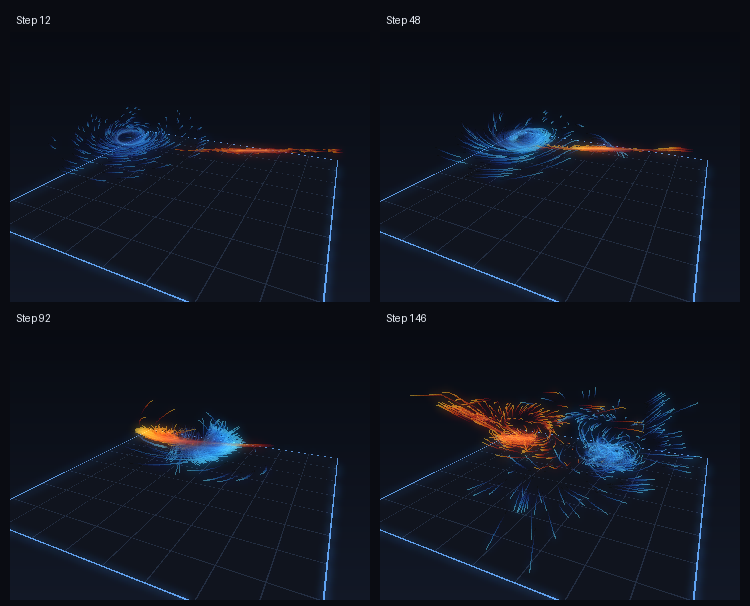

In [2]:
def render_nbody_frame(sim_obj, width=520, height=380, yaw=0.45, pitch=0.42, dist=2.25, pan_x=0.0, pan_y=0.0, trail_len=12, bloom=1.25):
    tdf = sim_obj.trail_dataframe(trail_len=trail_len)
    ox, oy = pan_x * 5.0, pan_y * 5.0
    shaded = vks.render_3d(
        tdf, "x", "y", "z", width=width, height=height,
        x_range=(-5.2 + ox, 5.2 + ox), y_range=(-5.2 + oy, 5.2 + oy), z_range=(-3.2, 3.2),
        kind="lines", color_by="trail_col", color_key=GAL_TRAIL_PALETTE,
        basemap=None, yaw=yaw, pitch=pitch, dist=dist, z_scale=0.65,
    )
    return apply_gpu_bloom(shaded.rgba, intensity=bloom, sigma=4.5)

sim.reset()
snaps = []
for target_step in (12, 48, 92, 145):
    while sim.step_count < target_step:
        sim.step(2)
    snaps.append((f"Step {sim.step_count}", render_nbody_frame(sim, width=360, height=270, trail_len=12, bloom=1.3)))

grid = Image.new("RGB", (2 * 370 + 10, 2 * 298 + 10), (10, 12, 18))
draw = ImageDraw.Draw(grid)
for idx, (lbl, im) in enumerate(snaps):
    r, c = divmod(idx, 2)
    x0, y0 = 10 + c * 370, 10 + r * 298
    draw.text((x0 + 6, y0 + 4), lbl, fill=(235, 240, 248))
    grid.paste(im, (x0, y0 + 22))
grid

## 2. Live Auto-Animating 3D N-Body Galaxy Merger (Drag to Orbit + Live Bloom & Trails!)

Watch the galaxies collide in real time on your Vulkan GPU — **drag** to orbit 360°, **Shift/Right-drag** to pan, **scroll** to zoom, and tweak **Bloom** & **Trail Length** live!

In [3]:
import io
import ipywidgets as widgets
from IPython.display import display
from vkshader.viewer3d import Interactive3DWidget

sim_live = VulkanNBodyGalaxies(n_per_galaxy=384)
for _ in range(8):
    sim_live.step(1)

st = {"yaw": 0.45, "pitch": 0.40, "dist": 2.15, "pan_x": 0.0, "pan_y": 0.0, "trail": 12, "bloom": 1.30}

def _frame_jpg():
    t0 = time.perf_counter()
    im = render_nbody_frame(
        sim_live, width=760, height=500,
        yaw=st["yaw"], pitch=st["pitch"], dist=st["dist"],
        pan_x=st["pan_x"], pan_y=st["pan_y"],
        trail_len=st["trail"], bloom=st["bloom"],
    )
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=86)
    return buf.getvalue(), (time.perf_counter() - t0) * 1000.0

jpg0, ms0 = _frame_jpg()
lbl = widgets.Label(value=f"Step {sim_live.step_count} | N={sim_live.N} | Frame: {ms0:.1f} ms")
w3d = None

def _redraw():
    jpg, ms = _frame_jpg()
    w3d.image_bytes = jpg
    lbl.value = f"Step {sim_live.step_count} | N={sim_live.N} | Bloom={st['bloom']:.2f} | Trails={st['trail']} | {ms:.1f} ms"

def _on_cam(yaw, pitch, dist, px, py):
    st.update(yaw=yaw, pitch=pitch, dist=dist, pan_x=px, pan_y=py)
    _redraw()

w3d = Interactive3DWidget(
    width=760, height=500,
    camera=(st["yaw"], st["pitch"], st["dist"], 0.0, 0.0),
    image_bytes=jpg0,
    on_camera_change=_on_cam,
)

play = widgets.Play(value=0, min=0, max=2000, step=1, interval=85, repeat=True, playing=True)
def _on_tick(_):
    sim_live.step(1)
    if sim_live.step_count > 260:
        sim_live.reset()
    _redraw()
play.observe(_on_tick, names="value")

btn_reset = widgets.Button(description="Reset Collision", button_style="warning")
btn_reset.on_click(lambda _: (sim_live.reset(), _redraw()))

sl_bloom = widgets.FloatSlider(value=1.30, min=0.0, max=2.5, step=0.1, description="Bloom:")
sl_bloom.observe(lambda ch: (st.update(bloom=ch["new"]), _redraw()), names="value")

sl_trail = widgets.IntSlider(value=12, min=2, max=16, step=1, description="Trails:")
sl_trail.observe(lambda ch: (st.update(trail=ch["new"]), _redraw()), names="value")

display(widgets.VBox([widgets.HBox([play, btn_reset, sl_bloom, sl_trail]), lbl, w3d]))